In [1]:
#%matplotlib notebook
#%matplotlib widget
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math
import os
singlecol = 3.5
plt.rcParams.update({'font.size': 8})
#plt.rcParams.update({'font.sans-serif': 'Helvetica'})
#plt.rcParams['font.family'] = 'dejavu'
plt.rcParams.update({'lines.linewidth':0.5})
plt.rcParams.update({'axes.linewidth':0.5})
plt.rcParams.update({'lines.markersize':2})
plt.rcParams.update({'savefig.dpi':200})
plt.rcParams.update({'legend.fontsize': 7})

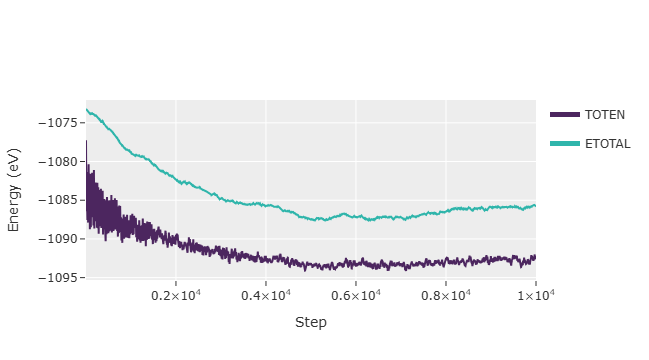

In [11]:
import py4vasp                       
path = "./pot_save/8_0/"
mycalc = py4vasp.Calculation.from_path(path)
mycalc.energy[:].plot( "TOTEN, ETOTAL" )

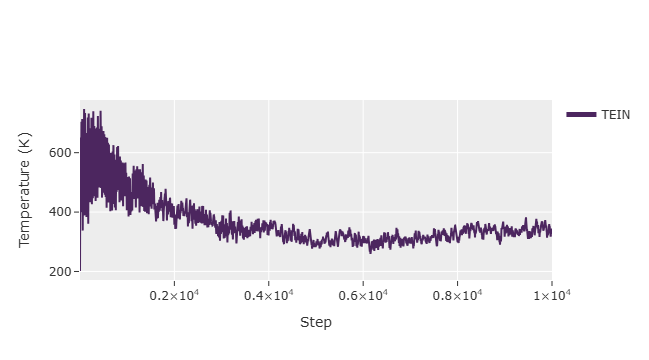

In [12]:
mycalc.energy[:].plot("TEIN")

In [16]:
mycalc.structure[0]

21.3563135098852754,0.0206763057805020,-0.0536412017163203
0.3141212978802153,10.6045865192023001,0.0265030075889517
-0.3146224102878118,0.2849568666707460,10.5903063311658858
0.2425222174419039,0.6818176076635192,0.5210862676957061
0.7465528839577567,0.6757382691477296,0.5213590595310077
0.2426384489361906,0.1712664009741524,0.0175551818536823
0.7408374124496697,0.1717706293519391,0.0276714952850452
0.2554044065125090,0.3334495616773132,0.4839715579691685
0.7553557890771374,0.3281258252619175,0.4760410516509415
0.2547284253367246,0.8248947897764140,0.9777596651084388
0.7513201412376738,0.8261370438052098,0.9797444105729293


/tmp/ipykernel_103933/335169099.py:5: UserWarning:

loadtxt: input contained no data: "./monitored_cell_volume.dat"



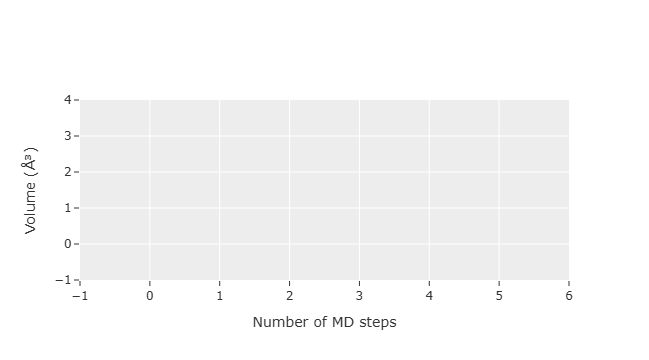

In [5]:
! cat ./REPORT | grep "mc> LV" > ./monitored_cell_volume.dat
from py4vasp import plot
import numpy as np

volume = np.loadtxt("./monitored_cell_volume.dat", usecols=2)

# plot the volume
plot(np.arange(len(volume))+1, volume, "relaxation", xlabel="Number of MD steps", ylabel="Volume (Å³)")

In [6]:
PCF = mycalc.pair_correlation[:].to_dict()

Text(0.5, 1.0, 'Pair Correlation Function')

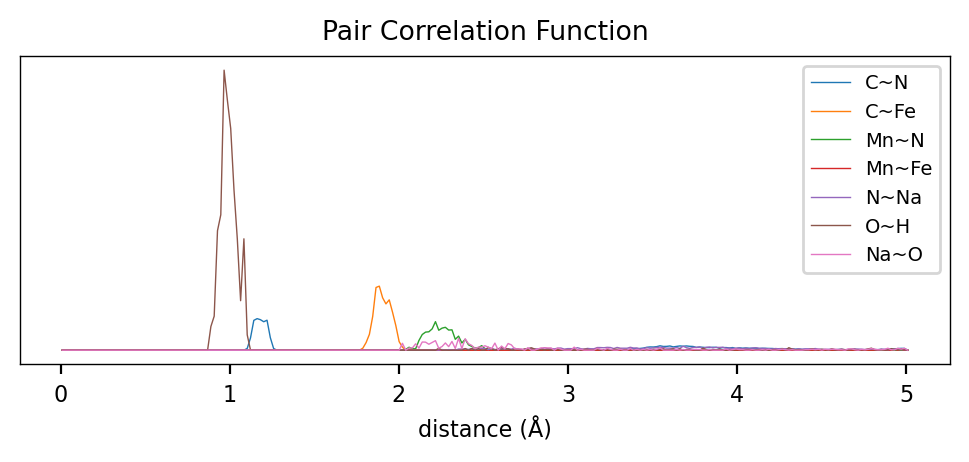

In [9]:
plt.figure(figsize = (6,2), dpi=200)
label_list=['C~N','C~Fe','Mn~N','Mn~Fe','N~Na', 'O~H', 'Na~O']
for i in range(len(label_list)):
    plt.plot(PCF['distances'], PCF[label_list[i]][0], label=label_list[i])
plt.xlabel('distance (Å)')
plt.yticks([])
plt.legend()
plt.title('Pair Correlation Function')

In [18]:
! grep ERR ML_LOGFILE > err.dat
t1, ERR = np.loadtxt("./err.dat", usecols=[1,3], unpack=True)

! grep BEEF ML_LOGFILE > beef.dat
t2, BEEF, CTIFOR = np.loadtxt("./beef.dat", usecols=[1,3,5], unpack=True)

! grep "STATUS" ML_LOGFILE|grep -E 'learning|critical'|grep -v "#" > status.dat
when_train = np.loadtxt("./status.dat", usecols=1)

! grep mag OSZICAR > cfg.dat
when_FP = np.loadtxt("./cfg.dat", usecols=0)

! grep 'T' OSZICAR | awk '{print $1, $3}' > time_temp.dat
step, temp = np.loadtxt("./time_temp.dat", usecols=[0,1], unpack=True)

/tmp/ipykernel_103933/2233232237.py:11: UserWarning:

loadtxt: input contained no data: "./cfg.dat"



IndexError: tuple index out of range

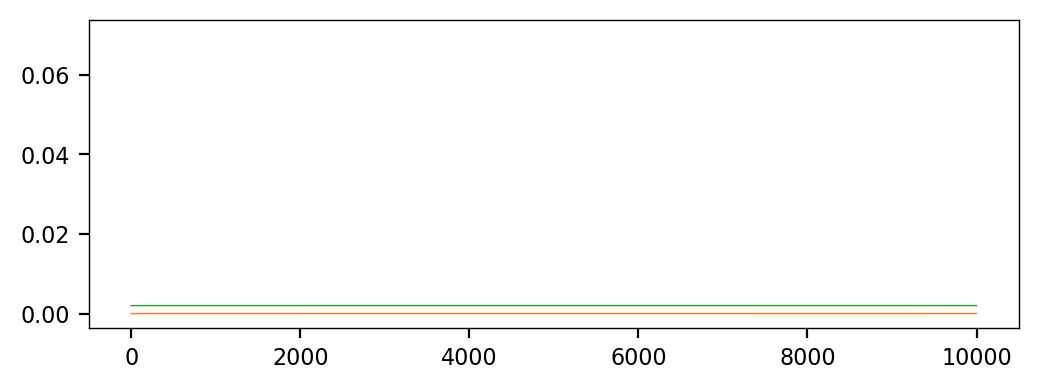

In [19]:
#plt.figure(figsize = (6,2), dpi=200)
fig, ax1 = plt.subplots(figsize = (6,2), dpi=200)
ax1.plot(t1, ERR, label='RMSE')
ax1.plot(t2, BEEF, label='Bayesian error')
ax1.plot(t2, CTIFOR, label='Threshold')
for i in range(when_FP.shape[0]):
    ax1.scatter(when_FP[i], BEEF[int(when_FP[i])-1], color='r', s=1)
for i in range(when_train.shape[0]):
    ax1.scatter(when_train[i], BEEF[int(when_train[i])-1], color='blue', s=1)
ax1.legend()
ax1.set_xlabel("Time step")
ax1.set_ylabel("Error in force (eV/Å)")

ax2 = ax1.twinx()
ax2.plot(when_FP, range(when_FP.shape[0]), '--', label='FP calculation', color='red')
ax2.plot(when_train, range(when_train.shape[0]), '--', label='Train MLFF', color='black')
ax2.set_ylabel('How many times')
ax2.legend()
plt.savefig('first run.png')

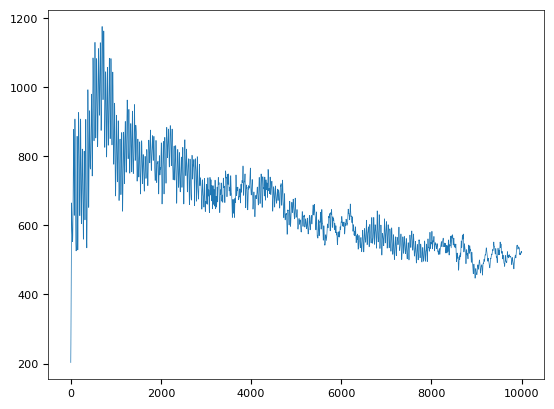

In [23]:
plt.plot(step, temp)

In [19]:
Force = mycalc.force[1].to_dict()
Force

{'structure': {'lattice_vectors': array([[ 2.13516257e+01,  3.51472359e-03, -4.26887679e-02],
         [ 3.14469064e-01,  1.06057957e+01,  1.62807874e-02],
         [-3.14636820e-01,  2.84969918e-01,  1.05907914e+01]]),
  'positions': array([[ 2.43042387e-01,  6.81076854e-01,  5.22074298e-01],
         [ 7.47385989e-01,  6.76066304e-01,  5.20822170e-01],
         [ 2.43149314e-01,  1.70825647e-01,  1.67906282e-02],
         [ 7.40201974e-01,  1.71438297e-01,  2.80429837e-02],
         [ 2.54760013e-01,  3.34605240e-01,  4.85478567e-01],
         [ 7.54520573e-01,  3.29167877e-01,  4.77373245e-01],
         [ 2.54118238e-01,  8.24956387e-01,  9.77263444e-01],
         [ 7.51616369e-01,  8.26105295e-01,  9.78734699e-01],
         [ 5.05352072e-01,  2.37911571e-02,  6.75227866e-01],
         [ 1.00794756e+00,  2.72655637e-02,  6.73432373e-01],
         [ 5.07484854e-01,  5.29628678e-01,  1.75961483e-01],
         [ 1.00709191e+00,  5.14828094e-01,  1.70026310e-01],
         [-7.04936507e-

In [ ]:
Force['structure']['lattice_vectors'][when_FP].shape

In [ ]:
Force['structure']['positions'].shape

In [ ]:
Force['structure']['elements']

In [ ]:
when_FP

## Remove H2O

In [4]:
for j in range(0,16,4):
    for i in range(4):
        random_numbers = [random.randint(0, 15) for _ in range(j)]
        remove_water_and_save('POSCAR_1', f'POSCAR_h2o_{16-j}_{i}', random_numbers)

NameError: name 'read_poscar' is not defined

In [5]:
import numpy as np

def read_poscar(filename):
    """
    Read a POSCAR file and return the crystal structure information.
    
    Parameters:
    filename (str): Path to the POSCAR file
    
    Returns:
    dict: Dictionary containing:
        - comment: First line comment
        - scaling_factor: Universal scaling factor
        - lattice: 3x3 lattice vector matrix
        - elements: List of element symbols
        - atom_counts: Number of atoms per element
        - coordinate_type: 'direct' or 'cartesian'
        - positions: Array of atomic positions
        - selective_dynamics: Boolean array if selective dynamics is present
    """
    with open(filename, 'r') as f:
        lines = f.readlines()
    
    # Initialize the structure dictionary
    structure = {}
    
    # First line is a comment
    structure['comment'] = lines[0].strip()
    
    # Second line is the universal scaling factor
    structure['scaling_factor'] = float(lines[1].strip())
    
    # Next three lines are the lattice vectors
    lattice = np.zeros((3, 3))
    for i in range(3):
        lattice[i] = [float(x) for x in lines[i+2].split()]
    structure['lattice'] = lattice * structure['scaling_factor']
    
    # Element symbols
    elements = lines[5].split()
    structure['elements'] = elements
    
    # Number of atoms per element
    atom_counts = [int(x) for x in lines[6].split()]
    structure['atom_counts'] = atom_counts
    total_atoms = sum(atom_counts)
    
    # Check for selective dynamics
    current_line = 7
    structure['selective_dynamics'] = False
    if lines[current_line].strip().upper().startswith('S'):
        structure['selective_dynamics'] = True
        current_line += 1
    
    # Coordinate type (Direct or Cartesian)
    coord_type = lines[current_line].strip().upper()
    structure['coordinate_type'] = 'direct' if coord_type.startswith('D') else 'cartesian'
    current_line += 1
    
    # Read atomic positions
    positions = np.zeros((total_atoms, 3))
    selective_flags = np.zeros((total_atoms, 3), dtype=bool)
    
    for i in range(total_atoms):
        line = lines[current_line + i].split()
        positions[i] = [float(x) for x in line[:3]]
        if structure['selective_dynamics']:
            selective_flags[i] = [x.upper().startswith('T') for x in line[3:6]]
    
    structure['positions'] = positions
    if structure['selective_dynamics']:
        structure['selective_flags'] = selective_flags
    
    return structure

def write_poscar(structure, filename):
    """
    Write structure data to a POSCAR file.
    
    Parameters:
    structure (dict): Dictionary containing structure information
    filename (str): Output file path
    """
    with open(filename, 'w') as f:
        # Write comment
        f.write(f"{structure['comment']}\n")
        
        # Write scaling factor
        f.write(f"{structure['scaling_factor']:.10f}\n")
        
        # Write lattice vectors
        for vector in structure['lattice'] / structure['scaling_factor']:
            f.write(f"{vector[0]:>20.10f}{vector[1]:>20.10f}{vector[2]:>20.10f}\n")
        
        # Write element symbols and counts
        f.write(' '.join(structure['elements']) + '\n')
        f.write(' '.join(str(x) for x in structure['atom_counts']) + '\n')
        
        # Write selective dynamics if present
        if structure['selective_dynamics']:
            f.write("Selective dynamics\n")
        
        # Write coordinate type
        f.write(f"{structure['coordinate_type']}\n")
        
        # Write positions and selective dynamics flags
        for i, pos in enumerate(structure['positions']):
            line = f"{pos[0]:>20.10f}{pos[1]:>20.10f}{pos[2]:>20.10f}"
            if structure['selective_dynamics']:
                flags = structure['selective_flags'][i]
                line += f"{'T' if flags[0] else 'F'} {'T' if flags[1] else 'F'} {'T' if flags[2] else 'F'}"
            f.write(line + '\n')

In [6]:
structure = read_poscar('./POSCAR_1')

In [7]:
structure

{'comment': 'C3 Mn N3, O, Na',
 'scaling_factor': 1.0,
 'lattice': array([[21.33488083,  0.        ,  0.        ],
        [ 0.31507396, 10.60943924,  0.        ],
        [-0.31507678,  0.28536839, 10.6056006 ]]),
 'elements': ['C', 'Mn', 'Fe', 'N', 'Na', 'O', 'H'],
 'atom_counts': [48, 8, 8, 48, 16, 16, 32],
 'selective_dynamics': False,
 'coordinate_type': 'cartesian',
 'positions': array([[ 5.42175499e+00,  7.40189406e+00,  5.50854880e+00],
        [ 1.60891954e+01,  7.40189406e+00,  5.50854880e+00],
        [ 5.42175641e+00,  1.95449024e+00,  2.05748498e-01],
        [ 1.60891968e+01,  1.95449024e+00,  2.05748498e-01],
        [ 5.24568259e+00,  3.49291374e+00,  5.09705196e+00],
        [ 1.59131230e+01,  3.49291374e+00,  5.09705196e+00],
        [ 5.24568118e+00,  8.94031756e+00,  1.03998523e+01],
        [ 1.59131216e+01,  8.94031756e+00,  1.03998523e+01],
        [ 1.04218652e+01,  4.00929179e-01,  7.25104909e+00],
        [ 2.10893057e+01,  4.00929179e-01,  7.25104909e+00],
  

In [8]:
H_atoms = structure['positions'][-32:]
O_atoms = structure['positions'][-48:-32]

### Find the index of each H2O

In [11]:
import numpy as np
from scipy.spatial.distance import cdist

def analyze_OH_bonds(O_atoms, H_atoms, lattice, oh_threshold=1.2):
    """
    Analyze which hydrogen atoms are bonded to which oxygen atoms.
    
    Parameters:
    O_atoms: numpy array of oxygen positions
    H_atoms: numpy array of hydrogen positions
    lattice: 3x3 lattice matrix
    oh_threshold: maximum O-H bond length in Angstroms (default 1.2)
    
    Returns:
    list of tuples: Each tuple contains (O_index, [H_indices])
    """
    def minimum_image_distance(pos1, pos2, lattice):
        """Calculate minimum image distance between two positions"""
        diff = pos1 - pos2
        # Convert to fractional coordinates
        inv_lattice = np.linalg.inv(lattice)
        frac_diff = np.dot(diff, inv_lattice)
        # Apply minimum image convention
        frac_diff = frac_diff - np.round(frac_diff)
        # Convert back to cartesian
        real_diff = np.dot(frac_diff, lattice)
        return np.linalg.norm(real_diff)

    bonds = []
    
    # For each oxygen atom
    for i, o_pos in enumerate(O_atoms):
        bonded_hydrogens = []
        
        # Check distance to each hydrogen
        for j, h_pos in enumerate(H_atoms):
            dist = minimum_image_distance(o_pos, h_pos, lattice)
            
            if dist < oh_threshold:
                bonded_hydrogens.append(j)
        
        bonds.append((i, bonded_hydrogens))
    
    return bonds

def print_water_analysis(bonds):
    """
    Print a human-readable analysis of water molecules.
    
    Parameters:
    bonds: list of tuples from analyze_OH_bonds
    """
    print("\nWater Molecule Analysis:")
    print("-----------------------")
    
    for o_idx, h_indices in bonds:
        if len(h_indices) == 0:
            print(f"Oxygen {o_idx}: No hydrogen bonds found")
        elif len(h_indices) == 1:
            print(f"Oxygen {o_idx}: Unusual - only one H atom (H{h_indices[0]})")
        elif len(h_indices) == 2:
            print(f"Oxygen {o_idx}: Normal water molecule - bonded to H{h_indices[0]} and H{h_indices[1]}")
        else:
            print(f"Oxygen {o_idx}: Unusual - bonded to {len(h_indices)} H atoms: {h_indices}")

# Example usage
def analyze_water_structure(structure, num_H=32, num_O=16):
    """
    Analyze water molecules in a structure.
    
    Parameters:
    structure: dict from read_poscar
    num_H: number of hydrogen atoms
    num_O: number of oxygen atoms
    """
    H_atoms = structure['positions'][-num_H:]
    O_atoms = structure['positions'][-num_H-num_O:-num_H]
    
    bonds = analyze_OH_bonds(O_atoms, H_atoms, structure['lattice'])
    print_water_analysis(bonds)
    
    return bonds

In [12]:
bonds = analyze_OH_bonds(O_atoms, H_atoms, structure['lattice'])
print_water_analysis(bonds)
#analyze_water_structure(structure)


Water Molecule Analysis:
-----------------------
Oxygen 0: Normal water molecule - bonded to H0 and H16
Oxygen 1: Normal water molecule - bonded to H1 and H17
Oxygen 2: Normal water molecule - bonded to H2 and H18
Oxygen 3: Normal water molecule - bonded to H3 and H19
Oxygen 4: Normal water molecule - bonded to H4 and H20
Oxygen 5: Normal water molecule - bonded to H5 and H21
Oxygen 6: Normal water molecule - bonded to H6 and H22
Oxygen 7: Normal water molecule - bonded to H7 and H23
Oxygen 8: Normal water molecule - bonded to H8 and H24
Oxygen 9: Normal water molecule - bonded to H9 and H25
Oxygen 10: Normal water molecule - bonded to H10 and H26
Oxygen 11: Normal water molecule - bonded to H11 and H27
Oxygen 12: Normal water molecule - bonded to H12 and H28
Oxygen 13: Normal water molecule - bonded to H13 and H29
Oxygen 14: Normal water molecule - bonded to H14 and H30
Oxygen 15: Normal water molecule - bonded to H15 and H31


In [14]:
structure

{'comment': 'C3 Mn N3, O, Na',
 'scaling_factor': 1.0,
 'lattice': array([[21.33488083,  0.        ,  0.        ],
        [ 0.31507396, 10.60943924,  0.        ],
        [-0.31507678,  0.28536839, 10.6056006 ]]),
 'elements': ['C', 'Mn', 'Fe', 'N', 'Na', 'O', 'H'],
 'atom_counts': [48, 8, 8, 48, 16, 16, 32],
 'selective_dynamics': False,
 'coordinate_type': 'cartesian',
 'positions': array([[ 5.42175499e+00,  7.40189406e+00,  5.50854880e+00],
        [ 1.60891954e+01,  7.40189406e+00,  5.50854880e+00],
        [ 5.42175641e+00,  1.95449024e+00,  2.05748498e-01],
        [ 1.60891968e+01,  1.95449024e+00,  2.05748498e-01],
        [ 5.24568259e+00,  3.49291374e+00,  5.09705196e+00],
        [ 1.59131230e+01,  3.49291374e+00,  5.09705196e+00],
        [ 5.24568118e+00,  8.94031756e+00,  1.03998523e+01],
        [ 1.59131216e+01,  8.94031756e+00,  1.03998523e+01],
        [ 1.04218652e+01,  4.00929179e-01,  7.25104909e+00],
        [ 2.10893057e+01,  4.00929179e-01,  7.25104909e+00],
  

In [ ]:
H2_ls = [-16:]
H1_ls = [-32:]
O_ls = [-48:]

### Remove H2O and write a new POSCAR

In [31]:
def remove_water_molecules(structure, molecules_to_remove):
    """
    Remove specific water molecules from the structure.
    
    Parameters:
    structure: dict from read_poscar
    molecules_to_remove: list of oxygen indices to remove (with their associated H atoms)
    
    Returns:
    dict: New structure with specified water molecules removed
    """
    # Create a deep copy of the structure to modify
    import copy
    new_structure = copy.deepcopy(structure)
    
    # Get the number of atoms
    num_H = structure['atom_counts'][-1]  # Assuming H is last
    num_O = structure['atom_counts'][-2]  # Assuming O is second to last
    
    # Calculate starting indices
    O_start = len(structure['positions']) - num_H - num_O
    H_start = len(structure['positions']) - num_H
    
    # First, identify all atoms to remove
    atoms_to_remove = set()
    
    # Analyze bonds to find associated H atoms
    H_atoms = structure['positions'][-32:]
    O_atoms = structure['positions'][-48:-32]
    bonds = analyze_OH_bonds(O_atoms, H_atoms, structure['lattice'])
    
    # For each water molecule to remove
    for o_idx in molecules_to_remove:
        # Add the oxygen atom index
        atoms_to_remove.add(O_start + o_idx)
        # Add the associated hydrogen indices
        for h_idx in bonds[o_idx][1]:
            atoms_to_remove.add(H_start + h_idx)
    
    # Convert to sorted list and reverse to remove from end first
    atoms_to_remove = sorted(list(atoms_to_remove), reverse=True)
    
    # Remove the atoms from positions array
    new_positions = np.delete(structure['positions'], atoms_to_remove, axis=0)
    new_structure['positions'] = new_positions
    
    # Update atom counts
    new_structure['atom_counts'][-2] -= len(molecules_to_remove)  # Update O count
    new_structure['atom_counts'][-1] -= 2 * len(molecules_to_remove)  # Update H count
    
    # If selective dynamics was present, update that too
    if 'selective_flags' in new_structure:
        new_flags = np.delete(structure['selective_flags'], atoms_to_remove, axis=0)
        new_structure['selective_flags'] = new_flags
    
    return new_structure

def remove_water_and_save(input_poscar, output_poscar, molecules_to_remove):
    """
    Load a POSCAR, remove specified water molecules, and save the new structure.
    
    Parameters:
    input_poscar: str, path to input POSCAR file
    output_poscar: str, path to output POSCAR file
    molecules_to_remove: list of oxygen indices to remove
    """
    # Load the structure
    structure = read_poscar(input_poscar)
    
    # Remove specified water molecules
    new_structure = remove_water_molecules(structure, molecules_to_remove)
    
    # Save the new structure
    write_poscar(new_structure, output_poscar)
    
    # Print summary
    print(f"Removed {len(molecules_to_remove)} water molecules")
    print(f"New structure has {new_structure['atom_counts'][-2]} O atoms and {new_structure['atom_counts'][-1]} H atoms")
    print(f"Saved to {output_poscar}")

In [32]:
for j in range(0,16,4):
    for i in range(4):
        random_numbers = generate_unique_numbers(count=j)
        remove_water_and_save('POSCAR_1', f'POSCAR_h2o_{16-j}_{i}', random_numbers)

Removed 0 water molecules
New structure has 16 O atoms and 32 H atoms
Saved to POSCAR_h2o_16_0
Removed 0 water molecules
New structure has 16 O atoms and 32 H atoms
Saved to POSCAR_h2o_16_1
Removed 0 water molecules
New structure has 16 O atoms and 32 H atoms
Saved to POSCAR_h2o_16_2
Removed 0 water molecules
New structure has 16 O atoms and 32 H atoms
Saved to POSCAR_h2o_16_3
Removed 4 water molecules
New structure has 12 O atoms and 24 H atoms
Saved to POSCAR_h2o_12_0
Removed 4 water molecules
New structure has 12 O atoms and 24 H atoms
Saved to POSCAR_h2o_12_1
Removed 4 water molecules
New structure has 12 O atoms and 24 H atoms
Saved to POSCAR_h2o_12_2
Removed 4 water molecules
New structure has 12 O atoms and 24 H atoms
Saved to POSCAR_h2o_12_3
Removed 8 water molecules
New structure has 8 O atoms and 16 H atoms
Saved to POSCAR_h2o_8_0
Removed 8 water molecules
New structure has 8 O atoms and 16 H atoms
Saved to POSCAR_h2o_8_1
Removed 8 water molecules
New structure has 8 O atoms 

In [28]:
import random

def generate_unique_numbers(count=4, min_val=0, max_val=15):
    """
    Generate unique random numbers within a specified range.
    
    Args:
        count (int): Number of unique numbers to generate
        min_val (int): Minimum value (inclusive)
        max_val (int): Maximum value (inclusive)
    
    Returns:
        list: List of unique random numbers
    """
    if count > (max_val - min_val + 1):
        raise ValueError("Cannot generate more unique numbers than the range allows")
    
    # Using random.sample ensures no repetition
    return random.sample(range(min_val, max_val + 1), count)

# Example usage
numbers = generate_unique_numbers(count=5)
print(numbers)

[13, 9, 2, 15, 14]


In [11]:
def remove_water_molecules(structure, molecules_to_remove):
    """
    Remove specified water molecules from the structure.
    
    Parameters:
    structure (dict): Original structure dictionary from read_poscar
    molecules_to_remove (list): List of oxygen atom indices to remove
    
    Returns:
    dict: Modified structure with specified water molecules removed
    """
    # Create a copy of the original structure to avoid modifying it
    new_structure = structure.copy()
    
    # Calculate the number of H and O atoms
    num_O = new_structure['atom_counts'][-2]
    num_H = new_structure['atom_counts'][-1]
    
    # Get current positions and elements
    all_positions = new_structure['positions']
    all_elements = []
    for elem, count in zip(new_structure['elements'][-2:], new_structure['atom_counts'][-2:]):
        all_elements.extend([elem] * count)
    
    # Indices of O and H atoms
    O_start_idx = len(all_positions) - num_H - num_O
    H_start_idx = len(all_positions) - num_H
    
    # Create lists to store remaining atoms
    remaining_positions = []
    remaining_elements = []
    
    # Track the number of removed O and H atoms
    removed_O_count = 0
    removed_H_count = 0
    
    # Process all atoms
    for i in range(len(all_positions)):
        if i >= O_start_idx and i < H_start_idx:
            # This is an oxygen atom
            if (i - O_start_idx) not in molecules_to_remove:
                remaining_positions.append(all_positions[i])
                remaining_elements.append(all_elements[i])
            else:
                removed_O_count += 1
        elif i >= H_start_idx:
            # This is a hydrogen atom
            # Remove H atoms corresponding to removed O atoms
            water_mol_idx = (i - H_start_idx) // 2
            if water_mol_idx not in molecules_to_remove:
                remaining_positions.append(all_positions[i])
                remaining_elements.append(all_elements[i])
            else:
                removed_H_count += 1
        else:
            # Keep all other atoms (non-water atoms)
            remaining_positions.append(all_positions[i])
            remaining_elements.append(all_elements[i])
    
    # Update the structure
    new_structure['positions'] = np.array(remaining_positions)
    
    # Update element list and counts
    unique_elements = list(dict.fromkeys(remaining_elements))
    new_structure['elements'] = unique_elements
    new_structure['atom_counts'] = [remaining_elements.count(elem) for elem in unique_elements]
    
    # Update comment to reflect modification
    new_structure['comment'] += f" - Removed {removed_O_count} water molecules"
    
    return new_structure

def remove_specific_waters(structure, num_O=16, num_H=32):
    """
    Interactively remove water molecules.
    
    Parameters:
    structure (dict): Original structure dictionary
    num_O (int): Number of oxygen atoms
    num_H (int): Number of hydrogen atoms
    
    Returns:
    dict: Modified structure
    """
    # Get O and H atoms
    O_atoms = structure['positions'][-num_O-num_H:-num_H]
    
    # Print out water molecules with their indices
    print("Water Molecules:")
    for i in range(len(O_atoms)):
        print(f"Molecule {i}: Oxygen at position {O_atoms[i]}")
    
    # Get user input for molecules to remove
    while True:
        try:
            remove_input = input("Enter indices of water molecules to remove (comma-separated, or 'done'): ")
            if remove_input.lower() == 'done':
                break
            
            molecules_to_remove = [int(x.strip()) for x in remove_input.split(',')]
            
            # Modify and save the structure
            modified_structure = remove_water_molecules(structure, molecules_to_remove)
            
            # Option to write to file
            output_filename = input("Enter output POSCAR filename (or press Enter to skip): ")
            if output_filename:
                write_poscar(modified_structure, output_filename)
                print(f"Modified structure saved to {output_filename}")
            
            return modified_structure
        
        except ValueError:
            print("Invalid input. Please enter valid molecule indices.")

In [37]:
structure = read_poscar('POSCAR')

# First, analyze the existing water molecules
# This will print out the current water molecule configuration
bonds = analyze_water_structure(structure)

# Method 1: Interactive water molecule removal
# This will prompt you in the console to:
# 1. See a list of water molecules
# 2. Choose which to remove
# 3. Optionally save the new structure
#modified_structure = remove_specific_waters(structure)

# Method 2: Programmatic water molecule removal
# Specify the indices of water molecules you want to remove
# Let's remove water molecules 0, 2, and 5
molecules_to_remove = [0, 2, 5]
modified_structure = remove_water_molecules(structure, molecules_to_remove)

# Write the modified structure to a new POSCAR file
write_poscar(modified_structure, 'POSCAR_modified')

# Analyze the new structure to verify water molecules
analyze_water_structure(modified_structure)


Water Molecule Analysis:
-----------------------
Oxygen 0: Normal water molecule - bonded to H0 and H16
Oxygen 1: Normal water molecule - bonded to H1 and H17
Oxygen 2: Normal water molecule - bonded to H2 and H18
Oxygen 3: Normal water molecule - bonded to H3 and H19
Oxygen 4: Normal water molecule - bonded to H4 and H20
Oxygen 5: Normal water molecule - bonded to H5 and H21
Oxygen 6: Normal water molecule - bonded to H6 and H22
Oxygen 7: Normal water molecule - bonded to H7 and H23
Oxygen 8: Normal water molecule - bonded to H8 and H24
Oxygen 9: Normal water molecule - bonded to H9 and H25
Oxygen 10: Normal water molecule - bonded to H10 and H26
Oxygen 11: Normal water molecule - bonded to H11 and H27
Oxygen 12: Normal water molecule - bonded to H12 and H28
Oxygen 13: Normal water molecule - bonded to H13 and H29
Oxygen 14: Normal water molecule - bonded to H14 and H30
Oxygen 15: Normal water molecule - bonded to H15 and H31


IndexError: list index out of range

In [40]:
def validate_water_removal_input(structure, molecules_to_remove, num_O=16, num_H=32):
    """
    Validate water molecule removal input.
    
    Parameters:
    structure (dict): Original structure dictionary
    molecules_to_remove (list): List of water molecule indices to remove
    num_O (int): Number of oxygen atoms
    num_H (int): Number of hydrogen atoms
    
    Returns:
    tuple: (is_valid, error_message)
    """
    # Sanity check on input
    if not isinstance(molecules_to_remove, list):
        return False, "Input must be a list of integers"
    
    # Calculate total number of water molecules
    total_waters = num_O
    
    # Check for invalid indices
    invalid_indices = [
        idx for idx in molecules_to_remove 
        if not isinstance(idx, int) or idx < 0 or idx >= total_waters
    ]
    
    if invalid_indices:
        return False, f"Invalid water molecule indices: {invalid_indices}. Valid range is 0-{total_waters-1}"
    
    # Remove duplicates while preserving order
    unique_molecules = []
    seen = set()
    for idx in molecules_to_remove:
        if idx not in seen:
            unique_molecules.append(idx)
            seen.add(idx)
    
    return True, unique_molecules

def safe_water_removal(structure, molecules_to_remove, num_O=16, num_H=32):
    """
    Safely remove water molecules with comprehensive error checking.
    
    Parameters:
    structure (dict): Original structure dictionary
    molecules_to_remove (list): List of water molecule indices to remove
    num_O (int): Number of oxygen atoms
    num_H (int): Number of hydrogen atoms
    
    Returns:
    dict or None: Modified structure or None if removal is invalid
    """
    # Validate input
    is_valid, result = validate_water_removal_input(
        structure, 
        molecules_to_remove, 
        num_O, 
        num_H
    )
    
    if not is_valid:
        print(f"Error: {result}")
        return None
    
    # If result is a list of unique, valid molecules
    try:
        modified_structure = remove_water_molecules(structure, result)
        return modified_structure
    except Exception as e:
        print(f"Unexpected error during water molecule removal: {e}")
        return None

def interactive_water_removal(structure, num_O=16, num_H=32):
    """
    Interactive water molecule removal with robust error handling.
    
    Parameters:
    structure (dict): Original structure dictionary
    num_O (int): Number of oxygen atoms
    num_H (int): Number of hydrogen atoms
    
    Returns:
    dict or None: Modified structure or None if no valid removal
    """
    # Get O atoms to display
    O_atoms = structure['positions'][-num_O-num_H:-num_H]
    
    # Print water molecules
    print("\nAvailable Water Molecules:")
    for i in range(len(O_atoms)):
        print(f"Molecule {i}: Oxygen at position {O_atoms[i]}")
    
    while True:
        try:
            # Prompt for input
            remove_input = input("\nEnter indices of water molecules to remove (comma-separated, or 'done'): ")
            
            # Exit condition
            if remove_input.lower() == 'done':
                return None
            
            # Convert input to list of integers
            molecules_to_remove = [int(x.strip()) for x in remove_input.split(',')]
            
            # Validate and remove
            modified_structure = safe_water_removal(
                structure, 
                molecules_to_remove, 
                num_O, 
                num_H
            )
            
            # If removal successful, offer to save
            if modified_structure:
                output_filename = input("Enter output POSCAR filename (or press Enter to skip): ")
                if output_filename:
                    write_poscar(modified_structure, output_filename)
                    print(f"Modified structure saved to {output_filename}")
                return modified_structure
        
        except ValueError:
            print("Invalid input. Please enter comma-separated integer indices.")

In [43]:
interactive_water_removal(structure)


Available Water Molecules:
Molecule 0: Oxygen at position [ 2.91484953 10.30250948  2.66942974]
Molecule 1: Oxygen at position [13.58228995 10.30250948  2.66942974]
Molecule 2: Oxygen at position [2.59977417 5.14047406 7.97223004]
Molecule 3: Oxygen at position [13.26721458  5.14047406  7.97223004]
Molecule 4: Oxygen at position [7.75258806 0.59229807 7.93617078]
Molecule 5: Oxygen at position [18.42002847  0.59229807  7.93617078]
Molecule 6: Oxygen at position [8.06766342 5.7543335  2.63337048]
Molecule 7: Oxygen at position [18.73510384  5.7543335   2.63337048]
Molecule 8: Oxygen at position [2.57640563 2.80289255 4.92418043]
Molecule 9: Oxygen at position [13.24384604  2.80289255  4.92418043]
Molecule 10: Oxygen at position [ 2.57640422  8.25029637 10.22698074]
Molecule 11: Oxygen at position [13.24384463  8.25029637 10.22698074]
Molecule 12: Oxygen at position [8.09103196 8.09191508 5.68142017]
Molecule 13: Oxygen at position [18.75847238  8.09191508  5.68142017]
Molecule 14: Oxyg


Enter indices of water molecules to remove (comma-separated, or 'done'):  [0]


Invalid input. Please enter comma-separated integer indices.



Enter indices of water molecules to remove (comma-separated, or 'done'):  0


Unexpected error during water molecule removal: list index out of range



Enter indices of water molecules to remove (comma-separated, or 'done'):  1


... (4 outputs left out)

Error: Invalid water molecule indices: [123]. Valid range is 0-15



Enter indices of water molecules to remove (comma-separated, or 'done'):  'done'


Invalid input. Please enter comma-separated integer indices.


KeyboardInterrupt: Interrupted by user

In [ ]:
# File paths
ml_abn_format_path = './ML_ABN_format.txt'
train_cfg_format_path = './train.cfg_format'

# Reading ML_ABN_format.txt
data = read_ml_abn_format(ml_abn_format_path)

# Writing to train.cfg_format
write_train_cfg_format(data, train_cfg_format_path)

In [ ]:
def extract_atom_counts(file_path):
    atom_counts = {}
    inside_atom_section = False

    with open(file_path, 'r') as file:
        for line in file:
            line = line.strip()
            if line.startswith("Atom types and atom numbers"):
                inside_atom_section = True
                continue
            if inside_atom_section:
                if line.startswith("="):
                    break
                parts = line.split()
                if len(parts) == 2:
                    atom, count = parts
                    atom_counts[atom] = int(count)
    
    return atom_counts

In [ ]:
def extract_lattice_vectors(file_path):
    lattice_vectors = []
    inside_lattice_section = False

    with open(file_path, 'r') as file:
        for line in file:
            line = line.strip()
            if line.startswith("Primitive lattice vectors (ang.)"):
                inside_lattice_section = True
                continue
            if inside_lattice_section:
                if line.startswith("="):
                    break
                parts = line.split()
                if len(parts) == 3:
                    vector = list(map(float, parts))
                    lattice_vectors.append(vector)
    
    return lattice_vectors

In [ ]:
def extract_atomic_positions(file_path):
    atomic_positions = []
    inside_positions_section = False

    with open(file_path, 'r') as file:
        for line in file:
            line = line.strip()
            if line.startswith("Atomic positions (ang.)"):
                inside_positions_section = True
                continue
            if inside_positions_section:
                if line.startswith("="):
                    break
                parts = line.split()
                if len(parts) == 3:
                    position = list(map(float, parts))
                    atomic_positions.append(position)
    
    return atomic_positions

In [ ]:
def extract_forces(file_path):
    force = []
    inside_force_section = False

    with open(file_path, 'r') as file:
        for line in file:
            line = line.strip()
            if line.startswith("Forces (eV ang.^-1)"):
                inside_force_section = True
                continue
            if inside_force_section:
                if line.startswith("="):
                    break
                parts = line.split()
                if len(parts) == 3:
                    position = list(map(float, parts))
                    force.append(position)
    
    return force

In [ ]:
def is_float(value):
    try:
        float(value)
        return True
    except ValueError:
        return False

def extract_stress(file_path):
    stress = []
    inside_stress_section = False

    with open(file_path, 'r') as file:
        for line in file:
            line = line.strip()
            if line.startswith("Stress (kbar)"):
                inside_stress_section = True
                continue
            if inside_stress_section:
                if line.startswith("="):
                    break
                parts = line.split()
                if len(parts) == 3 and is_float(parts[0]):
                    position = list(map(float, parts))
                    stress.append(position)
    
    return stress

In [ ]:
def extract_total_energy(file_path):
    inside_energy_section = False
    energy = []

    with open(file_path, 'r') as file:
        for line in file:
            line = line.strip()
            if line.startswith("Total energy (eV)"):
                inside_energy_section = True
                continue
            if inside_energy_section:
                if line.startswith("="):
                    break
                parts = line.split()
                if len(parts) == 1 and is_float(parts[0]):
                    position = list(map(float, parts))
                    energy.append(position)
    
    return energy

In [ ]:
import os

def extract_and_save_sections(file_path, output_dir):
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    sections = {}
    current_section = None
    current_content = []

    with open(file_path, 'r') as file:
        for line in file:
            line = line.strip()
            if line.startswith("Configuration num."):
                if current_section is not None:
                    config_num = current_section.split()[-1]
                    file_name = f"ML_ABN_{config_num}.txt"
                    file_path = os.path.join(output_dir, file_name)
                    with open(file_path, 'w') as section_file:
                        section_file.write("\n".join(current_content))
                    sections[config_num] = file_path
                    current_content = []
                current_section = line
                continue
            if current_section is not None:
                current_content.append(line)
        
        if current_section is not None:
            config_num = current_section.split()[-1]
            file_name = f"ML_ABN_{config_num}.txt"
            file_path = os.path.join(output_dir, file_name)
            with open(file_path, 'w') as section_file:
                section_file.write("\n".join(current_content))
            sections[config_num] = file_path

    return sections

In [ ]:
def write_train_cfg(sections, output_dir):
    atom_type_mapping = {'C': 0, 'Mn': 1, 'Fe': 2, 'N': 3, 'Na': 4}

    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
        
    for config_num, file_path in sections.items():
        atom_counts  = extract_atom_counts(file_path)
        lattice_vectors = extract_lattice_vectors(file_path)
        atomic_positions = extract_atomic_positions(file_path)
        forces = np.array(extract_forces(file_path))
        total_energy = extract_total_energy(file_path)[0][0]
        stress_tensor = extract_stress(file_path)

        atom_data = []
        atom_type_list = []
        for atom_type, count in atom_counts.items():
            atom_type_list.extend([atom_type_map[atom_type]] * count)
            
        file_name = f"train.cfg_{config_num}.txt"
        cfg_file_path = os.path.join(output_dir, file_name)
        
        with open(cfg_file_path, 'w') as file:
            file.write("BEGIN_CFG\n")
            file.write(f" Size\n")
            file.write(f"    {len(atomic_positions)}\n")
            file.write(" Supercell\n")
            for vec in lattice_vectors:
                file.write(f"    {'    '.join(f'{v:15.6f}' for v in vec)}\n")
            file.write(" AtomData:  id type       cartes_x      cartes_y      cartes_z           fx          fy          fz\n")
            for i, (pos, force) in enumerate(zip(atomic_positions, forces)):
                atom_type = atom_type_list[i]
                file.write(f"    {i+1:<3} {atom_type:<4} {'    '.join(f'{p:15.6f}' for p in pos)}    {'    '.join(f'{f:15.6f}' for f in force)}\n")
            file.write(f" Energy\n")
            file.write(f"    {total_energy:15.6f}\n")
            if stress_tensor:
                file.write(" PlusStress:  xx          yy          zz          yz          xz          xy\n")
                for tensor in stress_tensor:
                    file.write(f"    {'    '.join(f'{t:15.5f}' for t in tensor)}")
            file.write(" Feature   EFS_by       VASP\n")
            file.write("END_CFG\n")
            file.write("\n")

In [ ]:
file_path = 'ML_ABN'
output_dir = 'ML_ABN_2_cfg/ML_ABN'
sections = extract_and_save_sections(file_path, output_dir)

In [ ]:
# Example usage:
cfg_output_dir = 'ML_ABN_2_cfg/train.cfg'
write_train_cfg(sections, cfg_output_dir)

print(f"train.cfg files have been written to directory: {cfg_output_dir}")

In [ ]:
# Example usage:
file_path = './ML_ABN_format.txt'
#atom_counts, lattice_vectors, atomic_positions, forces, stress, energy= extract_structure(file_path)
atom_counts = extract_atomic_positions(file_path)
lattice_vectors =  np.array(extract_lattice_vectors(file_path))
atomic_positions =  np.array(extract_atomic_positions(file_path))
forces = np.array(extract_forces(file_path))
stress =  np.array(extract_stress(file_path))
total_energy = extract_total_energy(file_path)

In [ ]:
total_energy = extract_total_energy(file_path)
total_energy[0][0]

In [ ]:
file_path = './ML_ABN'
output_dir = 'ML_ABN_2_cfg'

sections = extract_sections(file_path)
write_sections_to_files(sections, output_dir)

In [ ]:
atom_list = ['C', 'Mn', 'Fe', 'N', 'Na']

In [ ]:
atom_counts = extract_atom_counts(file_path)
for i in range(len(atom_counts)):
    print(i)
    atom_numbers = [] 
    atom_numbers.append(atom_counts[atom_list[i]])
    
sum(atom_numbers)

In [ ]:
atom_numbers = sum(atom_counts.values())
atom_numbers

In [ ]:
atom_counts